In [1]:
%load_ext pyspecdata.ipy
from itertools import cycle
import matplotlib.pyplot as plt
import numpy as np

First, we load our files, and just see what the data looks like

In [2]:
d1 = find_file("240510_TS_C10_W20_run1.DSC", exp_type="francklab_esr/romana") # cooling 1 --initial sample
d2 = find_file("240510_TS_C10_W20_run2.DSC", exp_type="francklab_esr/romana") # heating 2 subsequently --after cooling and heating

In [3]:
d1.shape  # this shows me what the dimensions are

[(1024, '$B_0$'), (31, 'Temperature'), (10, 'harmonic')]

In [4]:
d2.shape

[(1024, '$B_0$'), (31, 'Temperature'), (10, 'harmonic')]

In [5]:
d1.chunk_auto("harmonic", "harmonic")  # the harmonic is typically stored so that we need to do this
d1.shape  # this shows me what the dimensions are

[(1024, '$B_0$'), (31, 'Temperature'), (2, 'phase'), (5, 'harmonic')]

In [6]:
d2.chunk_auto("harmonic", "harmonic")
d2.shape

[(1024, '$B_0$'), (31, 'Temperature'), (2, 'phase'), (5, 'harmonic')]

I start by plotting as a 2D pcolor plot:

Text(0.5, 1.0, 'TEMPO-SO$_4$ w$_0= 20$ in Dodecane for cooling1')

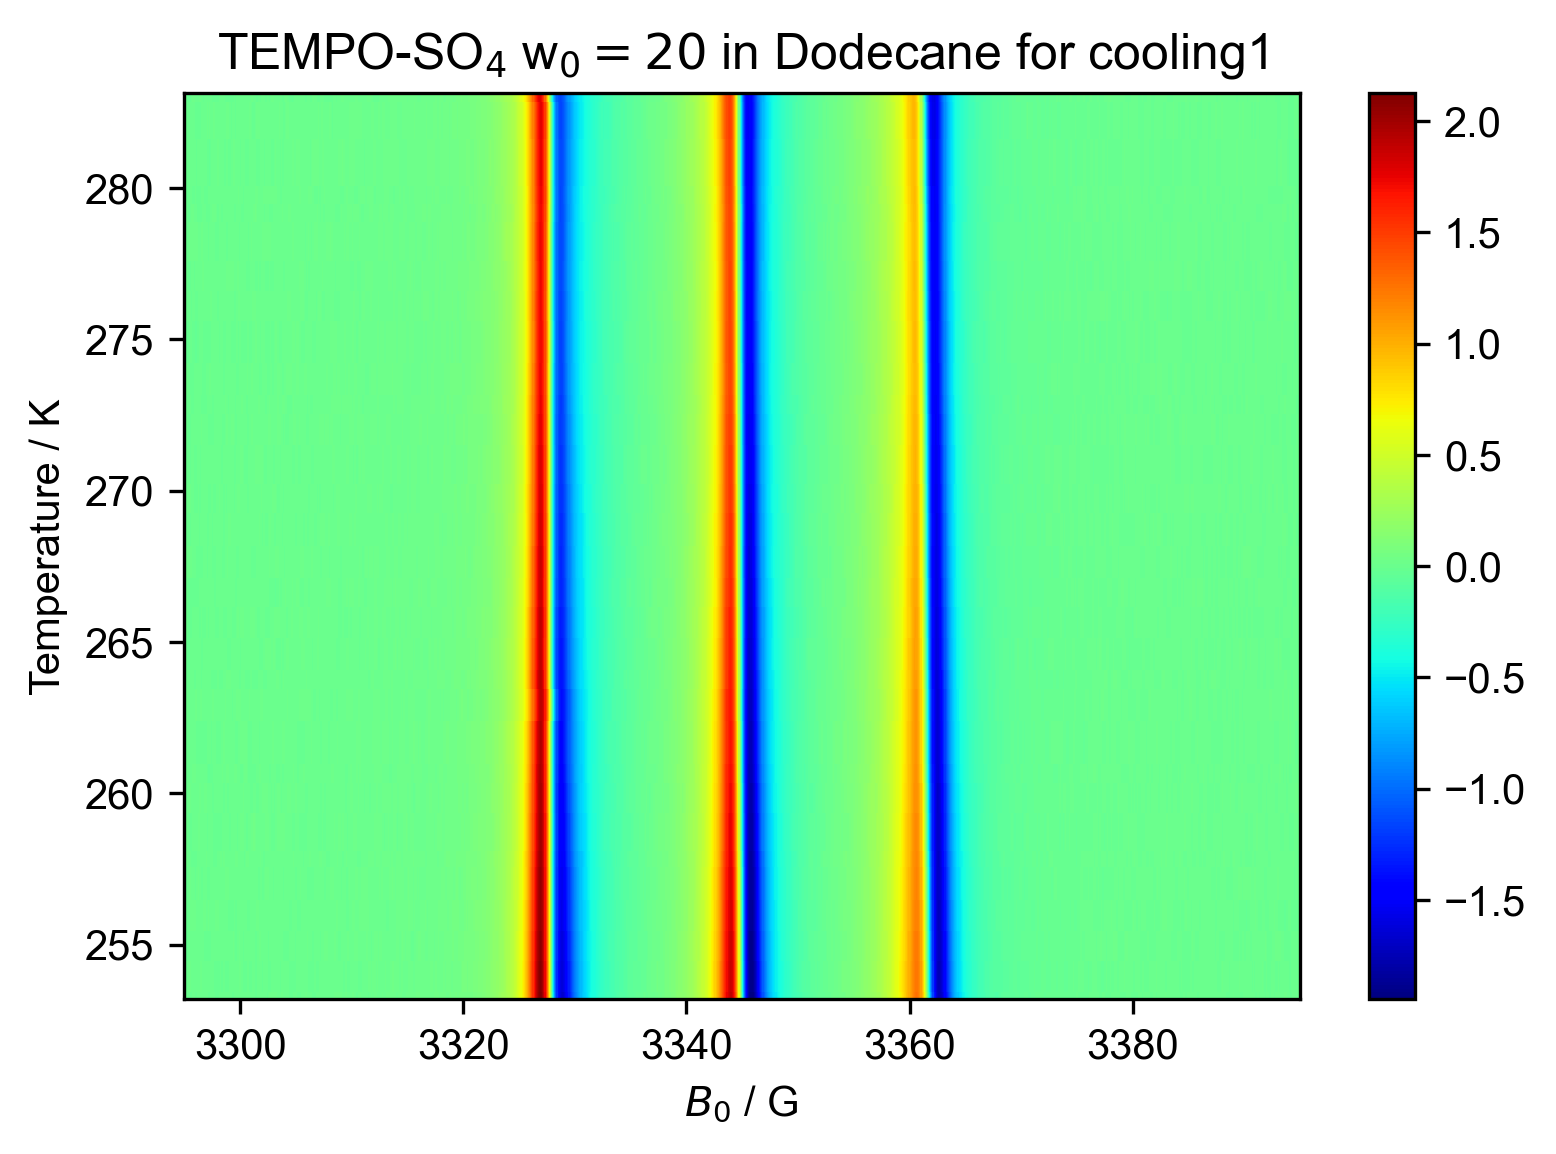

In [7]:
figure(dpi=300)
d1 = d1["harmonic", 0]["phase", 0]  # select only the "standard" EPR -- ignore the higher harmonics.  Make sure you can parse this!
d1.sort('Temperature')
d1.reorder("Temperature").pcolor()
title("TEMPO-SO$_4$ w$_0= 20$ in Dodecane for cooling1")

Text(0.5, 1.0, 'TEMPO-SO$_4$ w$_0= 20$ in Dodecane for heating1')

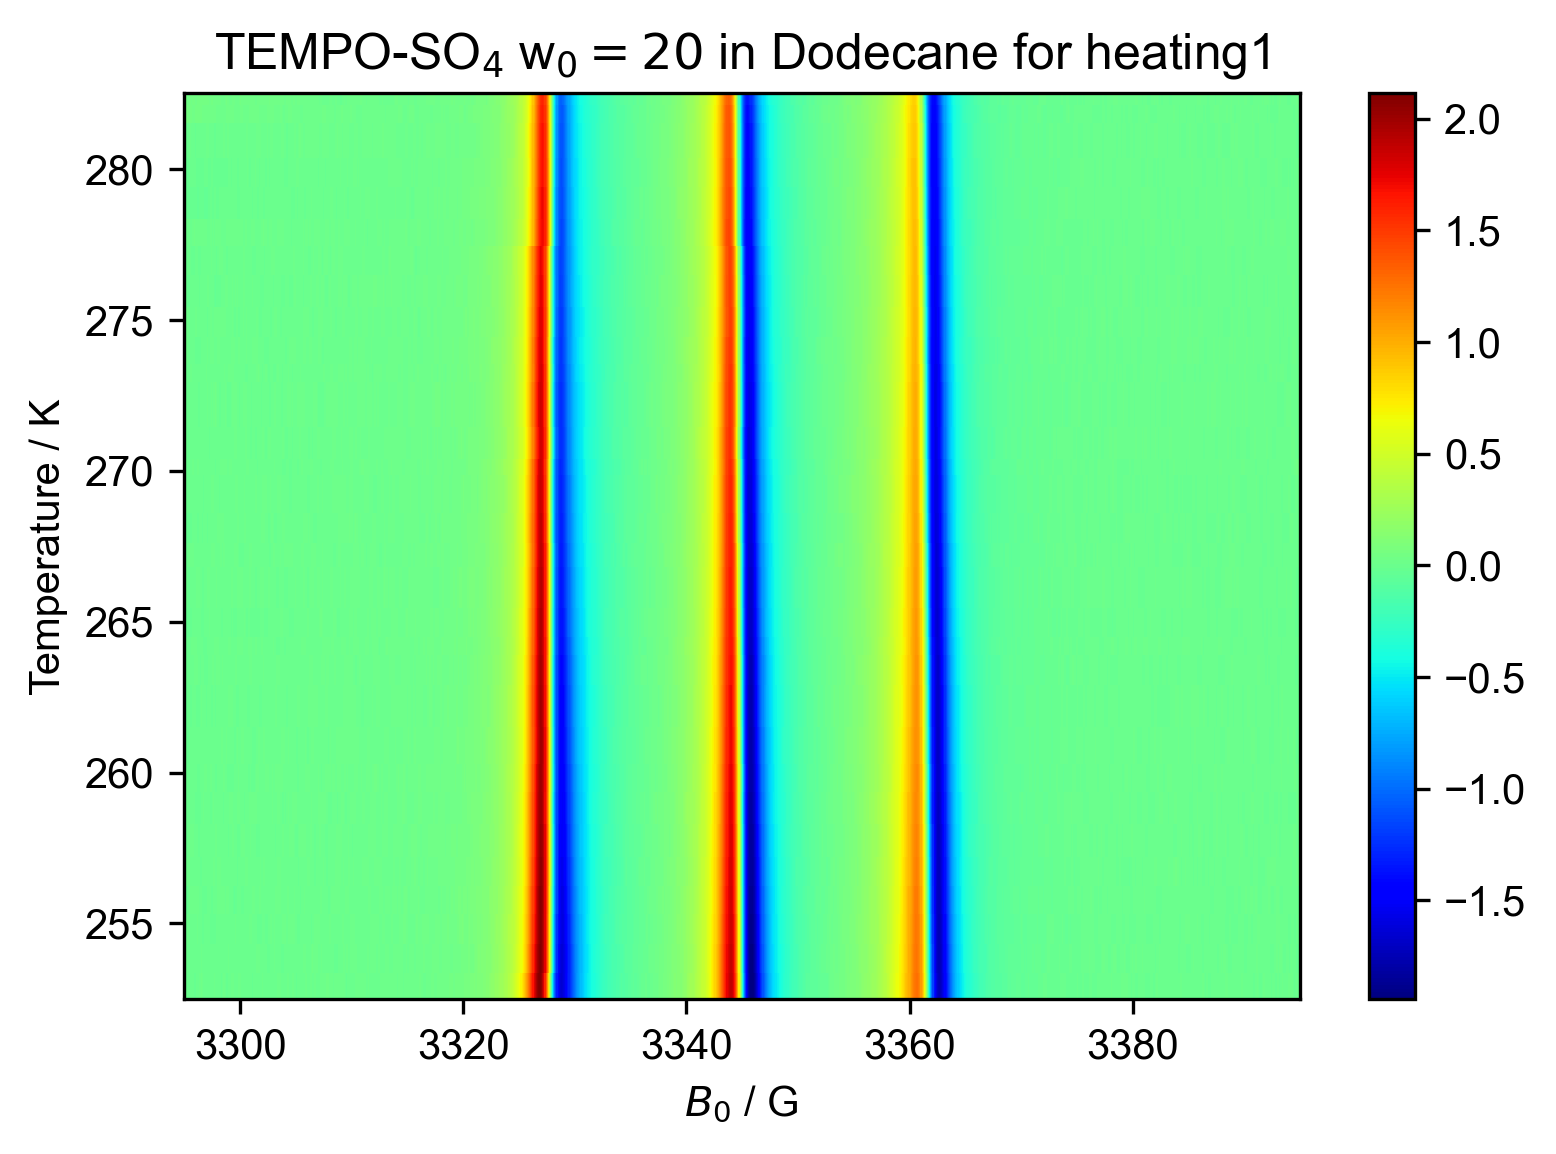

In [8]:
figure(dpi=300)
d2 = d2["harmonic", 0]["phase", 0]
d2.sort('Temperature')
d2.reorder("Temperature").pcolor()
title("TEMPO-SO$_4$ w$_0= 20$ in Dodecane for heating1")

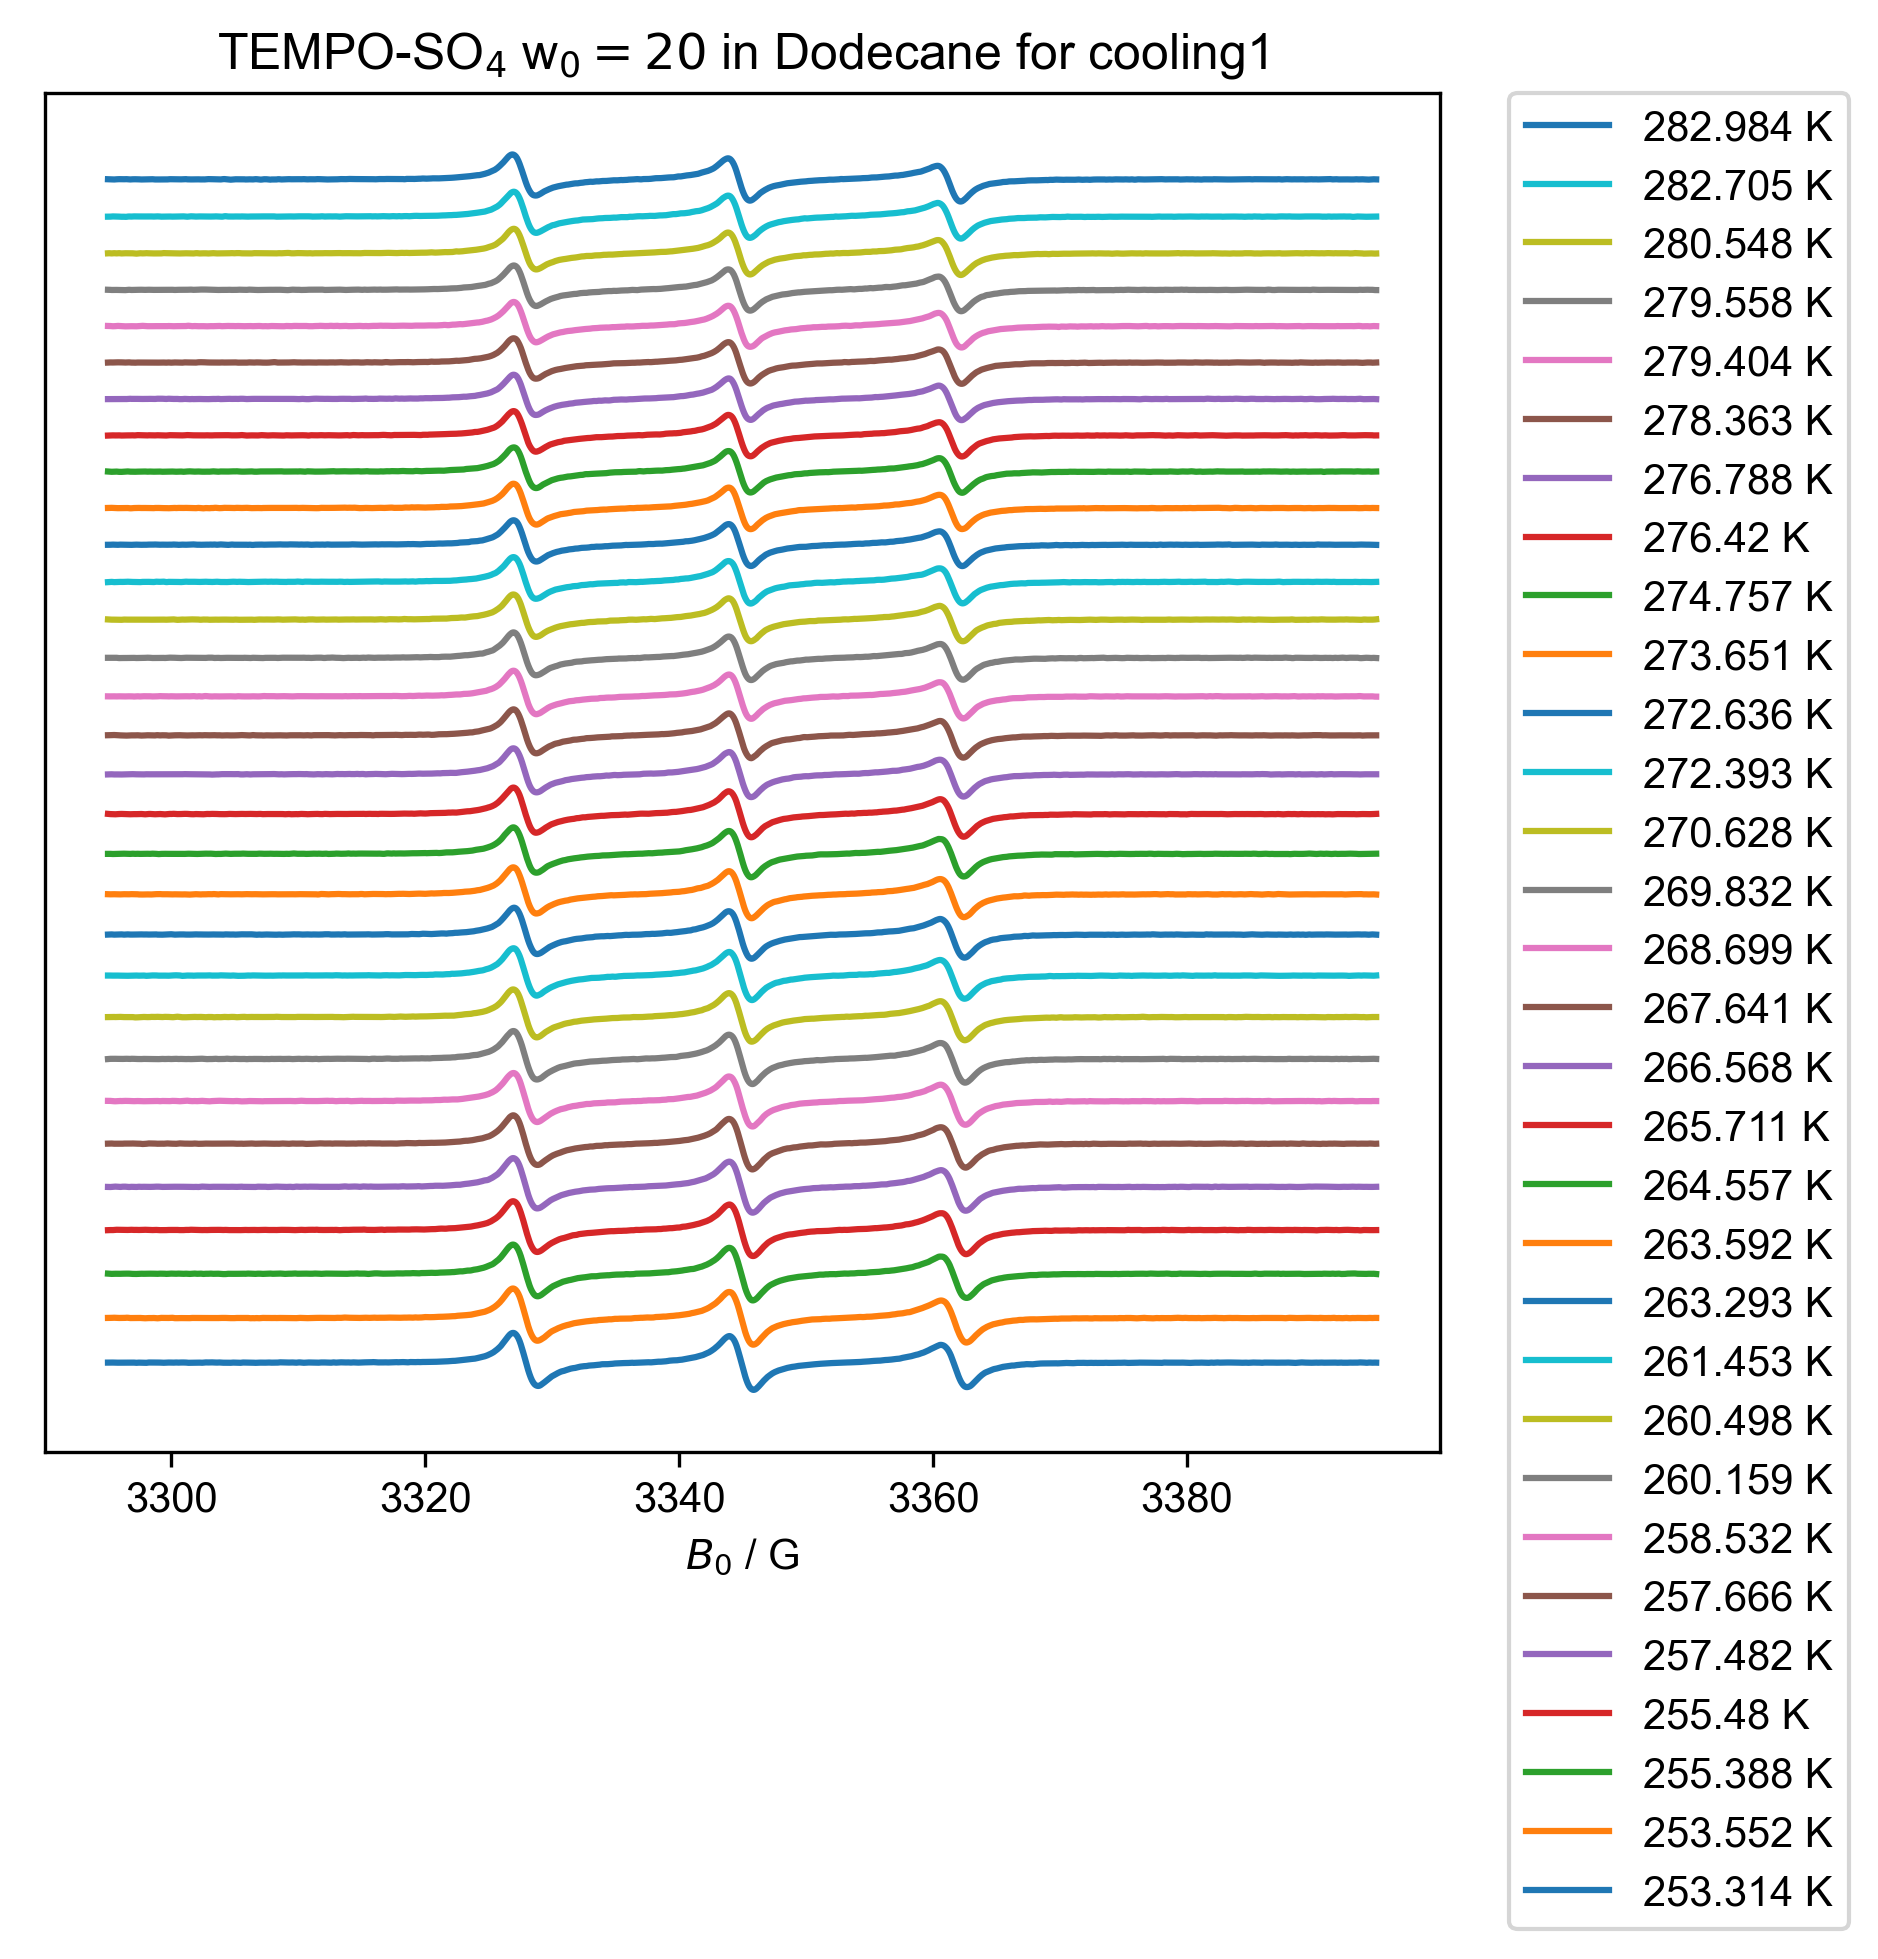

In [9]:
#cooling same plot in offset
offset= 0

for this_label, temp_range in [
    ("TEMPO-SO$_4$ w$_0= 20$ in Dodecane for cooling1", (200, 300))
]:
    this_d1 = d1["Temperature":temp_range]
    figure(dpi=300, figsize=(6,6)) # this is standard matplotlib to open a new figure
    title(this_label)
    for temp_ithis_dx in range(this_d1.shape["Temperature"]):
        this_temp = this_d1.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d1["Temperature", temp_ithis_dx] + offset, label=f"{this_temp} K")        
        offset += this_d1["Temperature", temp_ithis_dx].max()*1.5
        ax=plt.gca()
        ax.set_yticks([])
        ax.set_ylabel(None)
        handles, labels = plt.gca().get_legend_handles_labels()
        handles.reverse()
        labels.reverse()
        legend(handles, labels, bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)

#     fancy_legend()

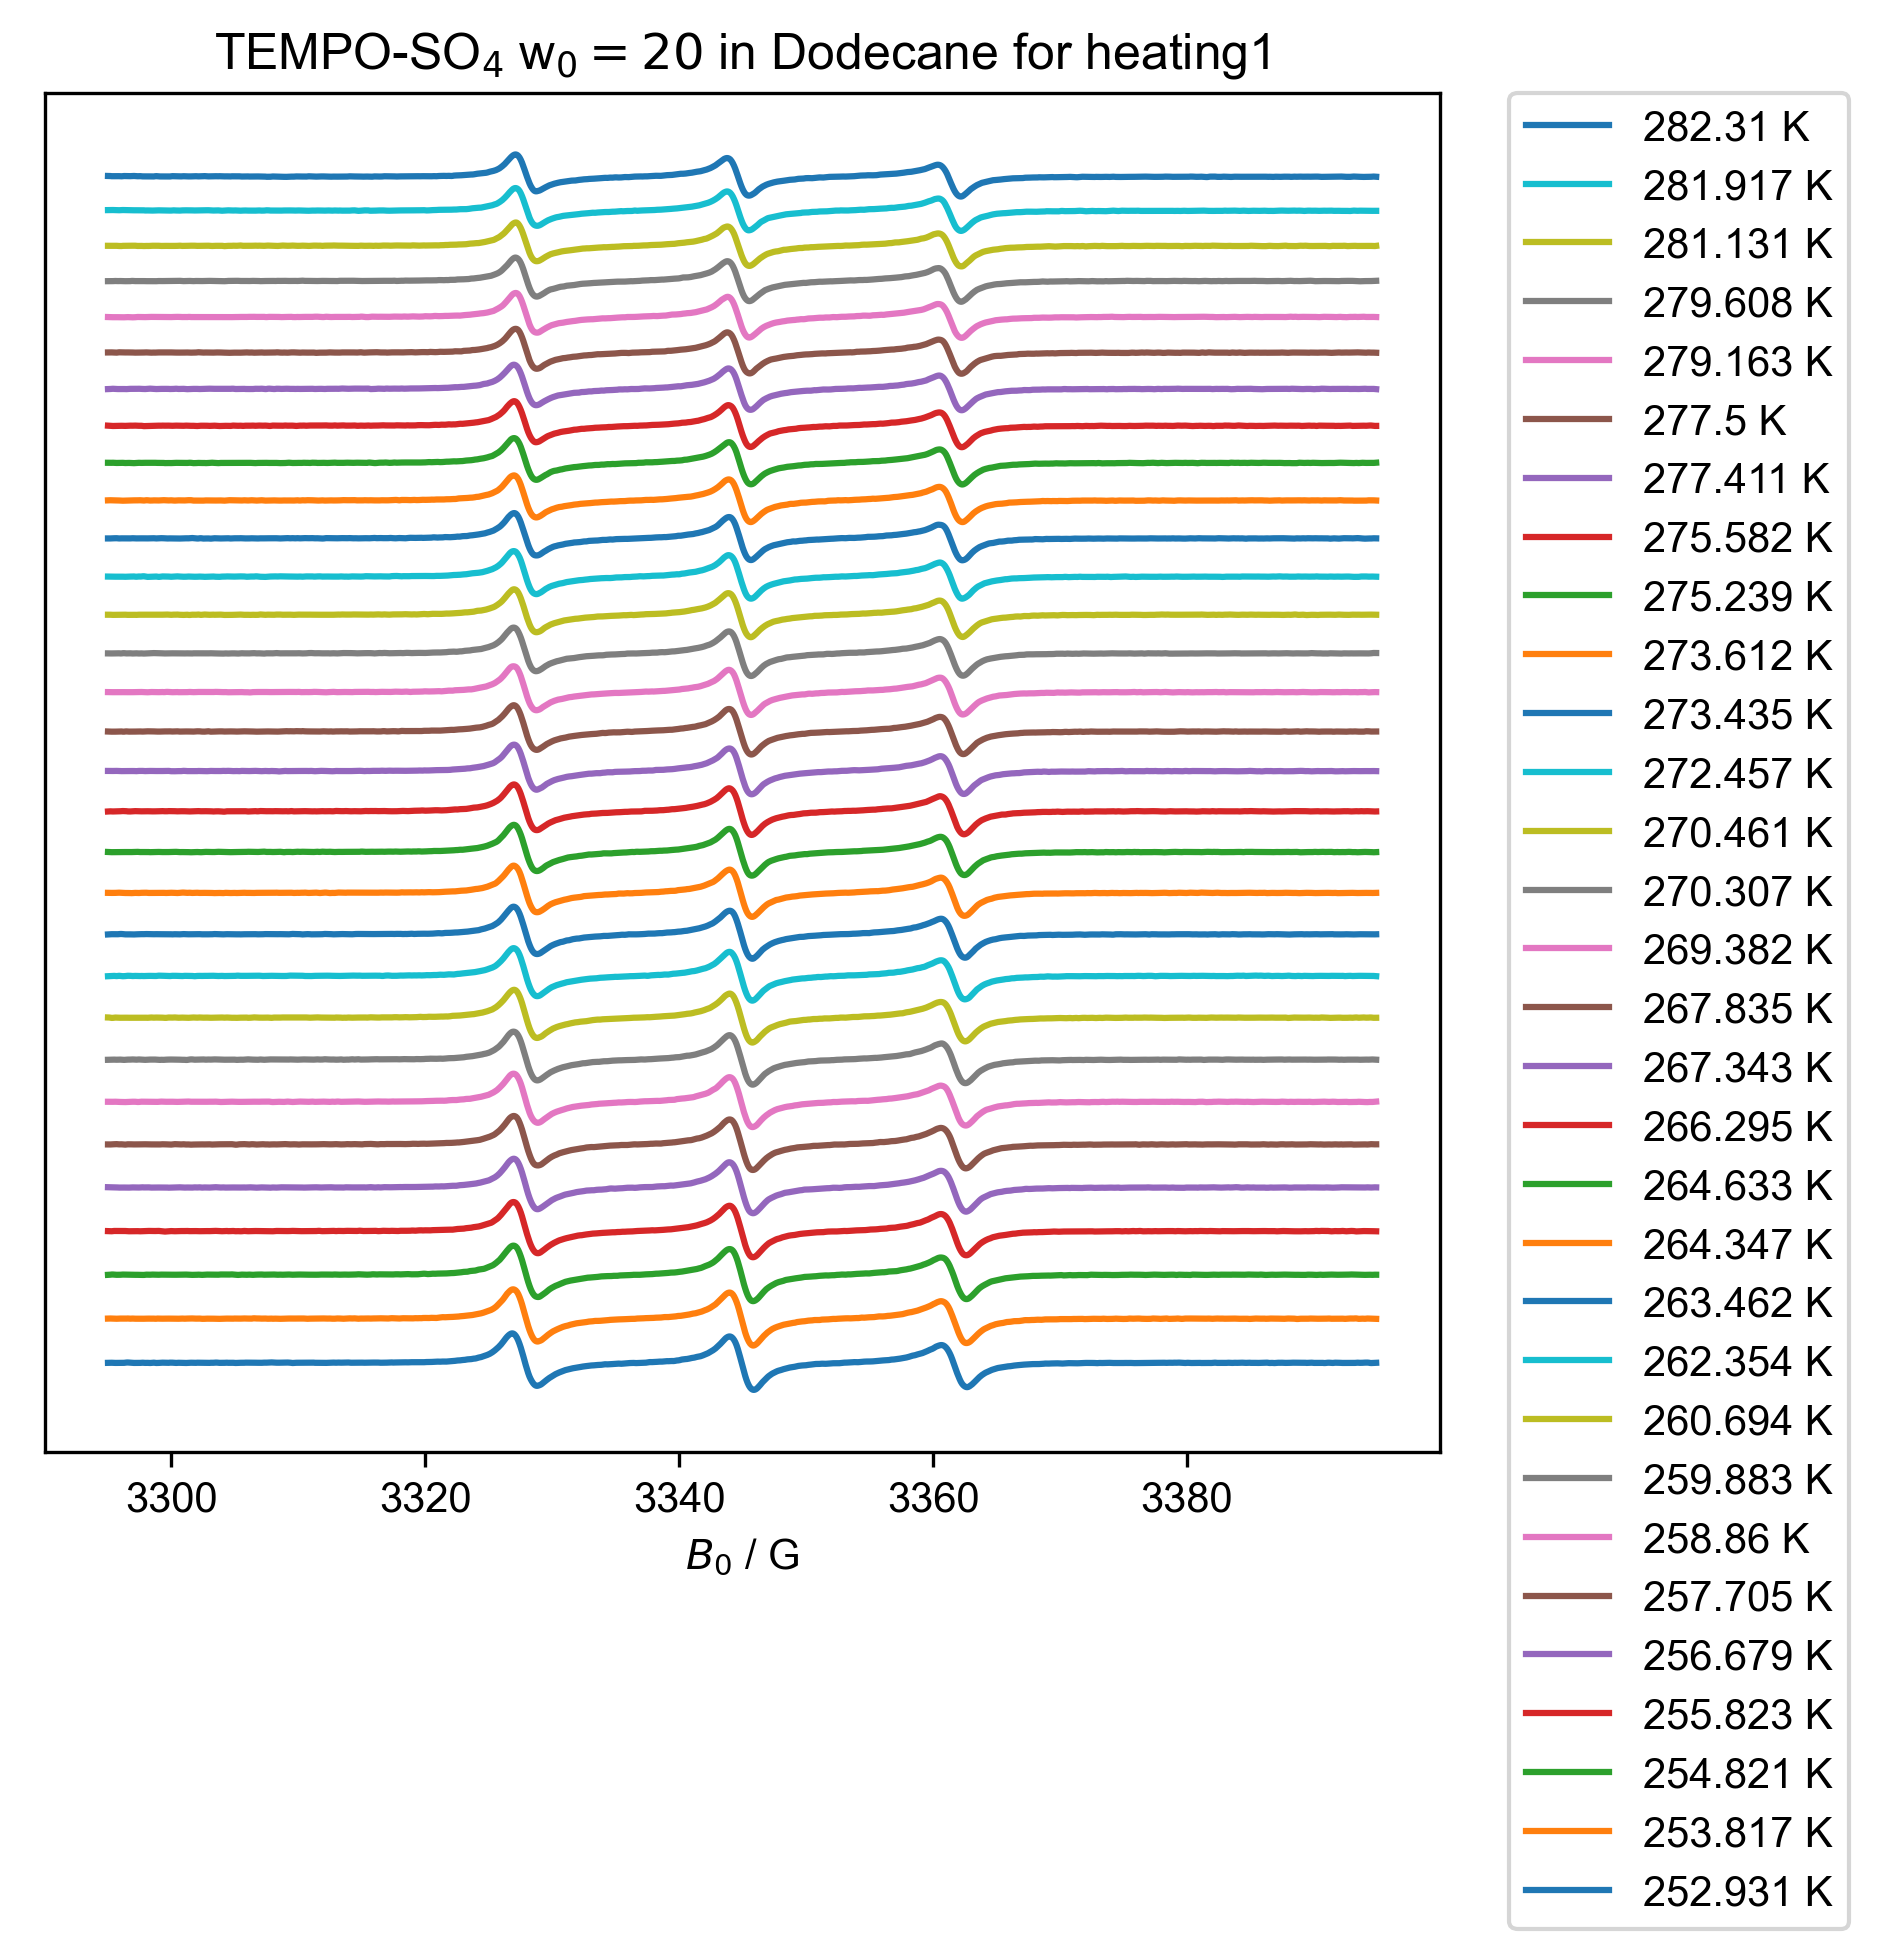

In [10]:
#heating run2 in same plot
offset =0

for this_label, temp_range in [
    ("TEMPO-SO$_4$ w$_0=20$ in Dodecane for heating1", (173, 373)),
]:
    this_d2 = d2["Temperature":temp_range]
    figure(dpi=300, figsize=(6,6)) # this is standard matplotlib to open a new figure
    title(this_label)
    for temp_ithis_dx in range(this_d2.shape["Temperature"]):
        this_temp = this_d2.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d2["Temperature", temp_ithis_dx] + offset, label=f"{this_temp} K")
        offset += this_d2["Temperature", temp_ithis_dx].max()*1.5
        ax=plt.gca()
        ax.set_yticks([])
        ax.set_ylabel(None)
        handles, labels = plt.gca().get_legend_handles_labels()
        handles.reverse()
        labels.reverse()
        legend(handles, labels, bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)

#     fancy_legend()

[253.314 253.552 255.388 255.48  257.482 257.666 258.532 260.159 260.498
 261.453 263.293 263.592 264.557 265.711 266.568 267.641 268.699 269.832
 270.628 272.393 272.636 273.651 274.757 276.42  276.788 278.363 279.404
 279.558 280.548 282.705 282.984]
[252.931 253.817 254.821 255.823 256.679 257.705 258.86  259.883 260.694
 262.354 263.462 264.347 264.633 266.295 267.343 267.835 269.382 270.307
 270.461 272.457 273.435 273.612 275.239 275.582 277.411 277.5   279.163
 279.608 281.131 281.917 282.31 ]


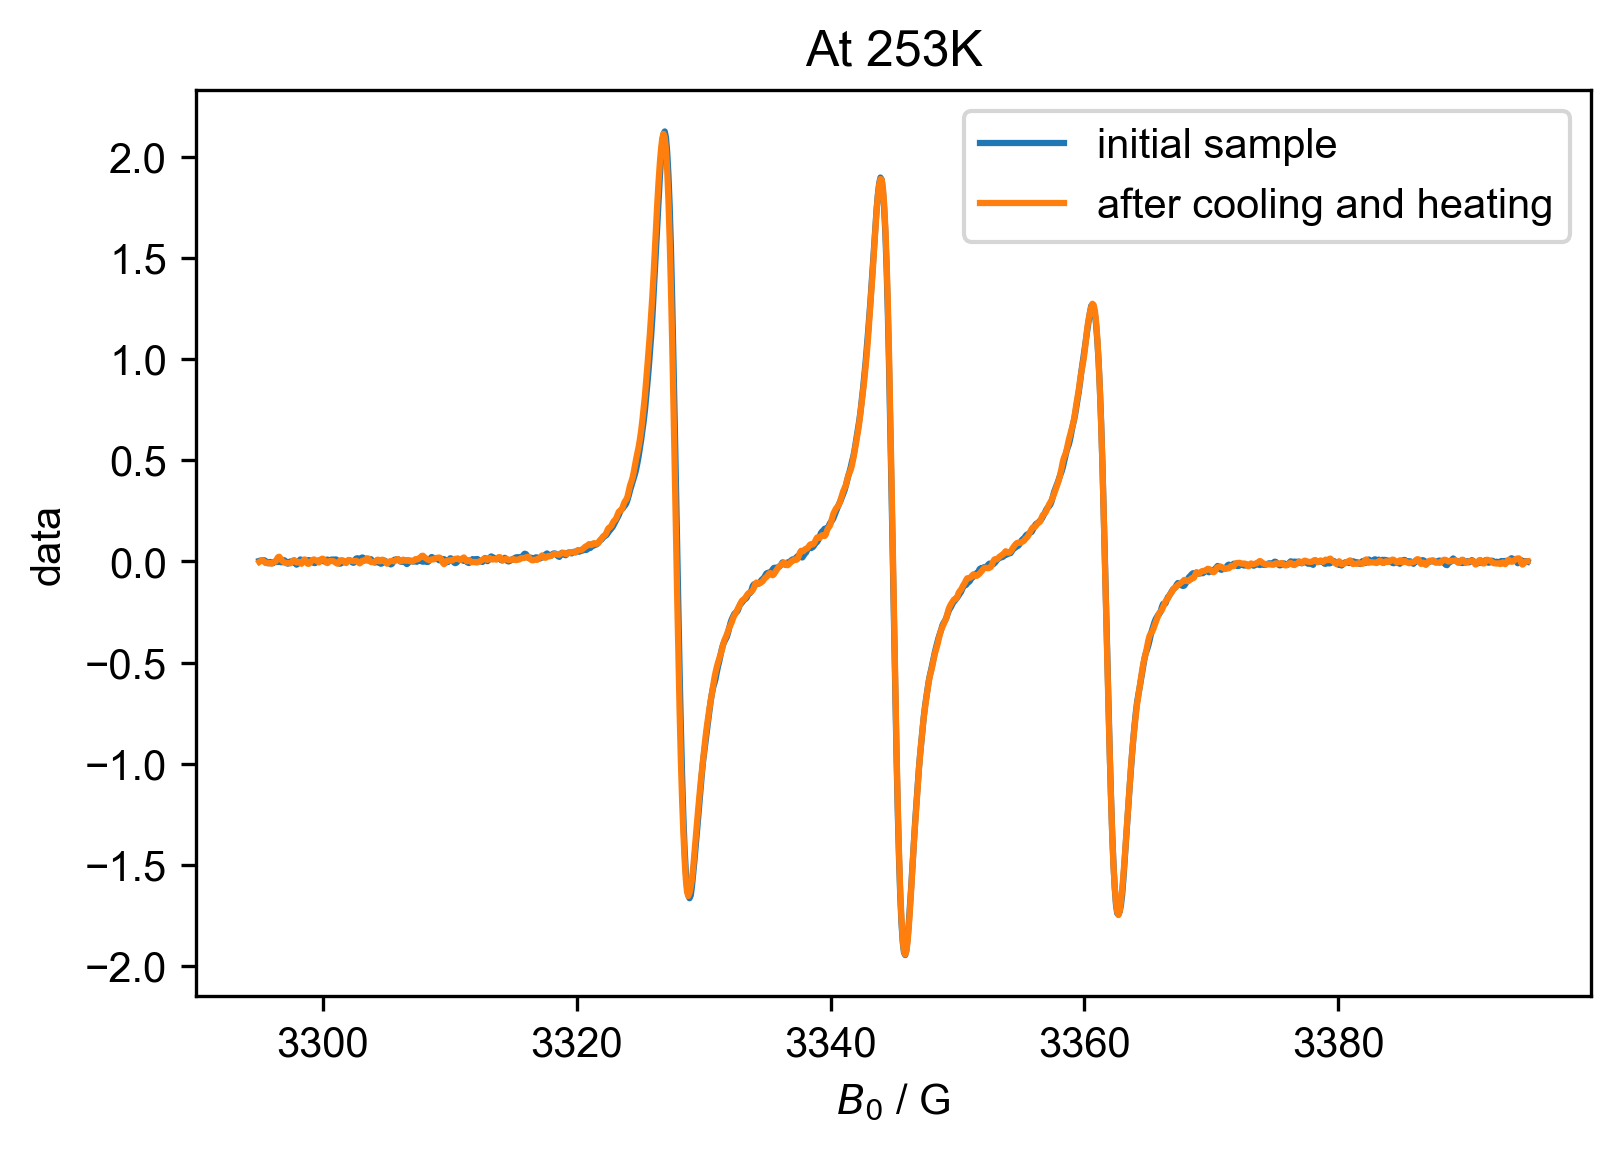

In [11]:
#near room temperature
print(d1.getaxis("Temperature"))
print(d2.getaxis("Temperature"))
figure(dpi=300, figsize=(6,4))
plot(d1["Temperature":253], label="initial sample")
plot(d2["Temperature":253], label="after cooling and heating")
title("At 253K")
legend()

[253.314 253.552 255.388 255.48  257.482 257.666 258.532 260.159 260.498
 261.453 263.293 263.592 264.557 265.711 266.568 267.641 268.699 269.832
 270.628 272.393 272.636 273.651 274.757 276.42  276.788 278.363 279.404
 279.558 280.548 282.705 282.984]
[252.931 253.817 254.821 255.823 256.679 257.705 258.86  259.883 260.694
 262.354 263.462 264.347 264.633 266.295 267.343 267.835 269.382 270.307
 270.461 272.457 273.435 273.612 275.239 275.582 277.411 277.5   279.163
 279.608 281.131 281.917 282.31 ]


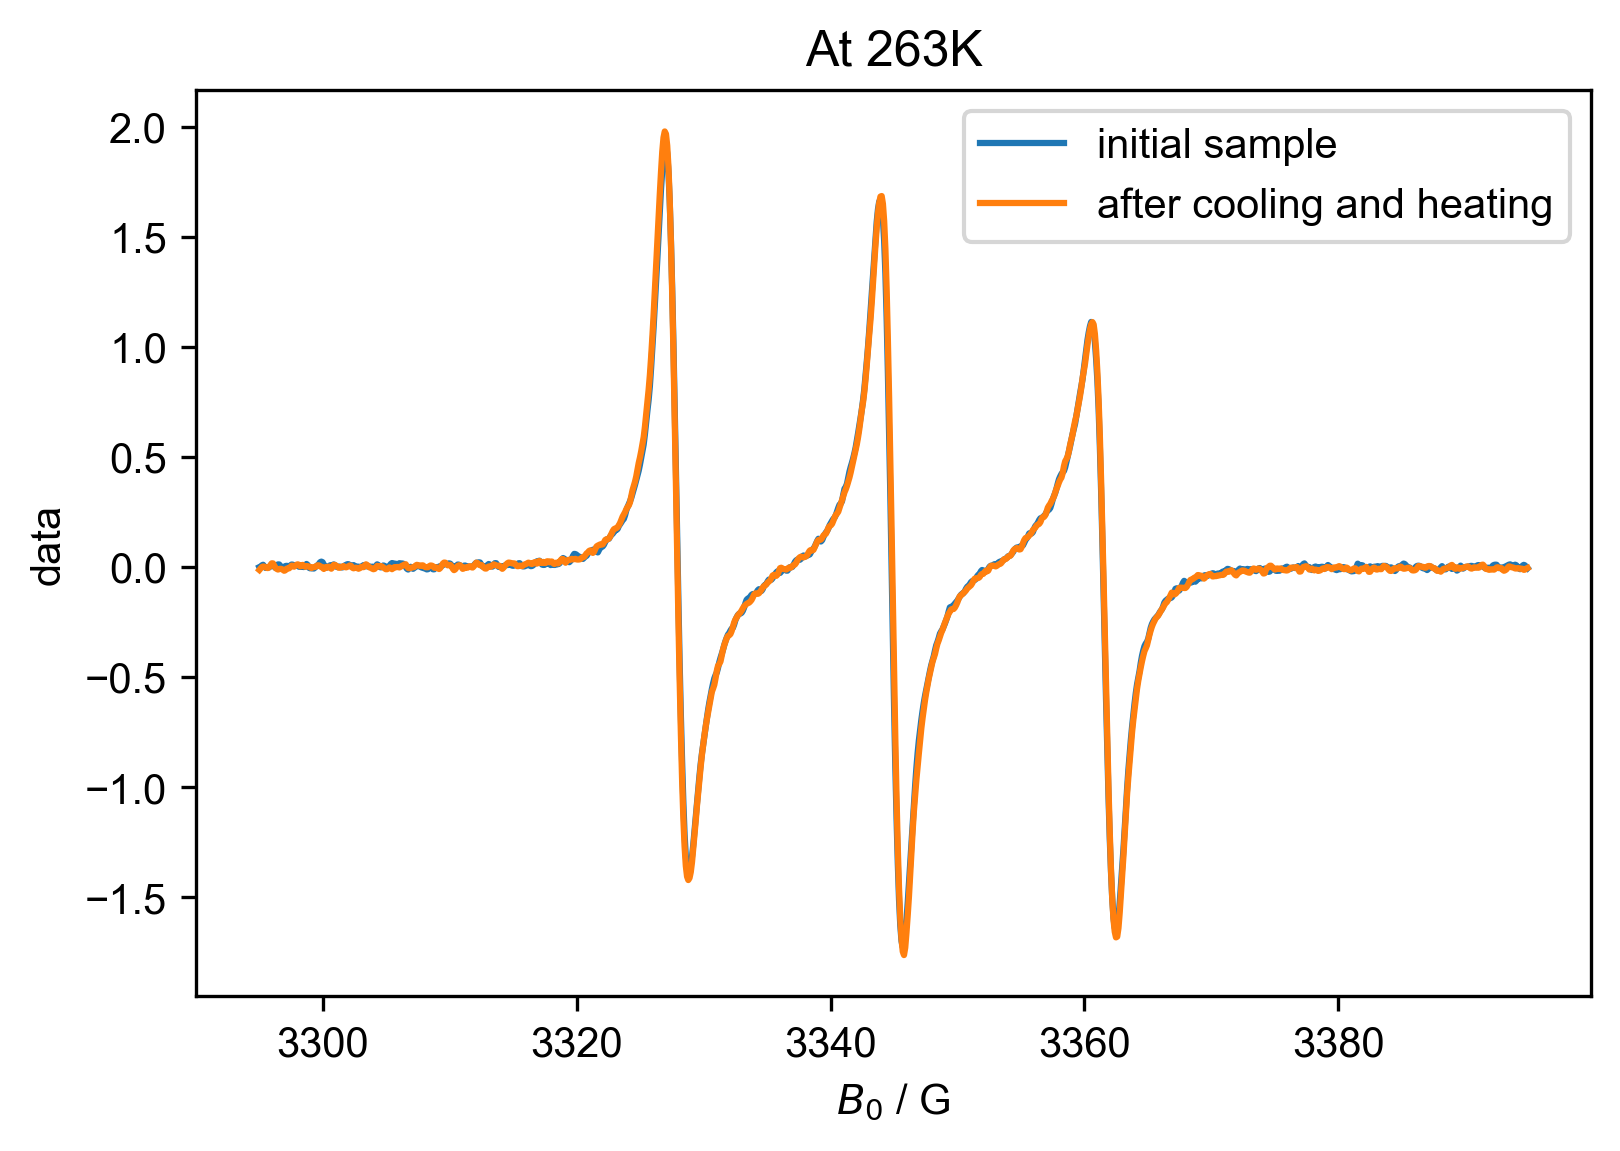

In [12]:
#near room temperature
print(d1.getaxis("Temperature"))
print(d2.getaxis("Temperature"))
figure(dpi=300, figsize=(6,4))
plot(d1["Temperature":263], label="initial sample")
plot(d2["Temperature":263], label="after cooling and heating")
title("At 263K")
legend()

[253.314 253.552 255.388 255.48  257.482 257.666 258.532 260.159 260.498
 261.453 263.293 263.592 264.557 265.711 266.568 267.641 268.699 269.832
 270.628 272.393 272.636 273.651 274.757 276.42  276.788 278.363 279.404
 279.558 280.548 282.705 282.984]
[252.931 253.817 254.821 255.823 256.679 257.705 258.86  259.883 260.694
 262.354 263.462 264.347 264.633 266.295 267.343 267.835 269.382 270.307
 270.461 272.457 273.435 273.612 275.239 275.582 277.411 277.5   279.163
 279.608 281.131 281.917 282.31 ]


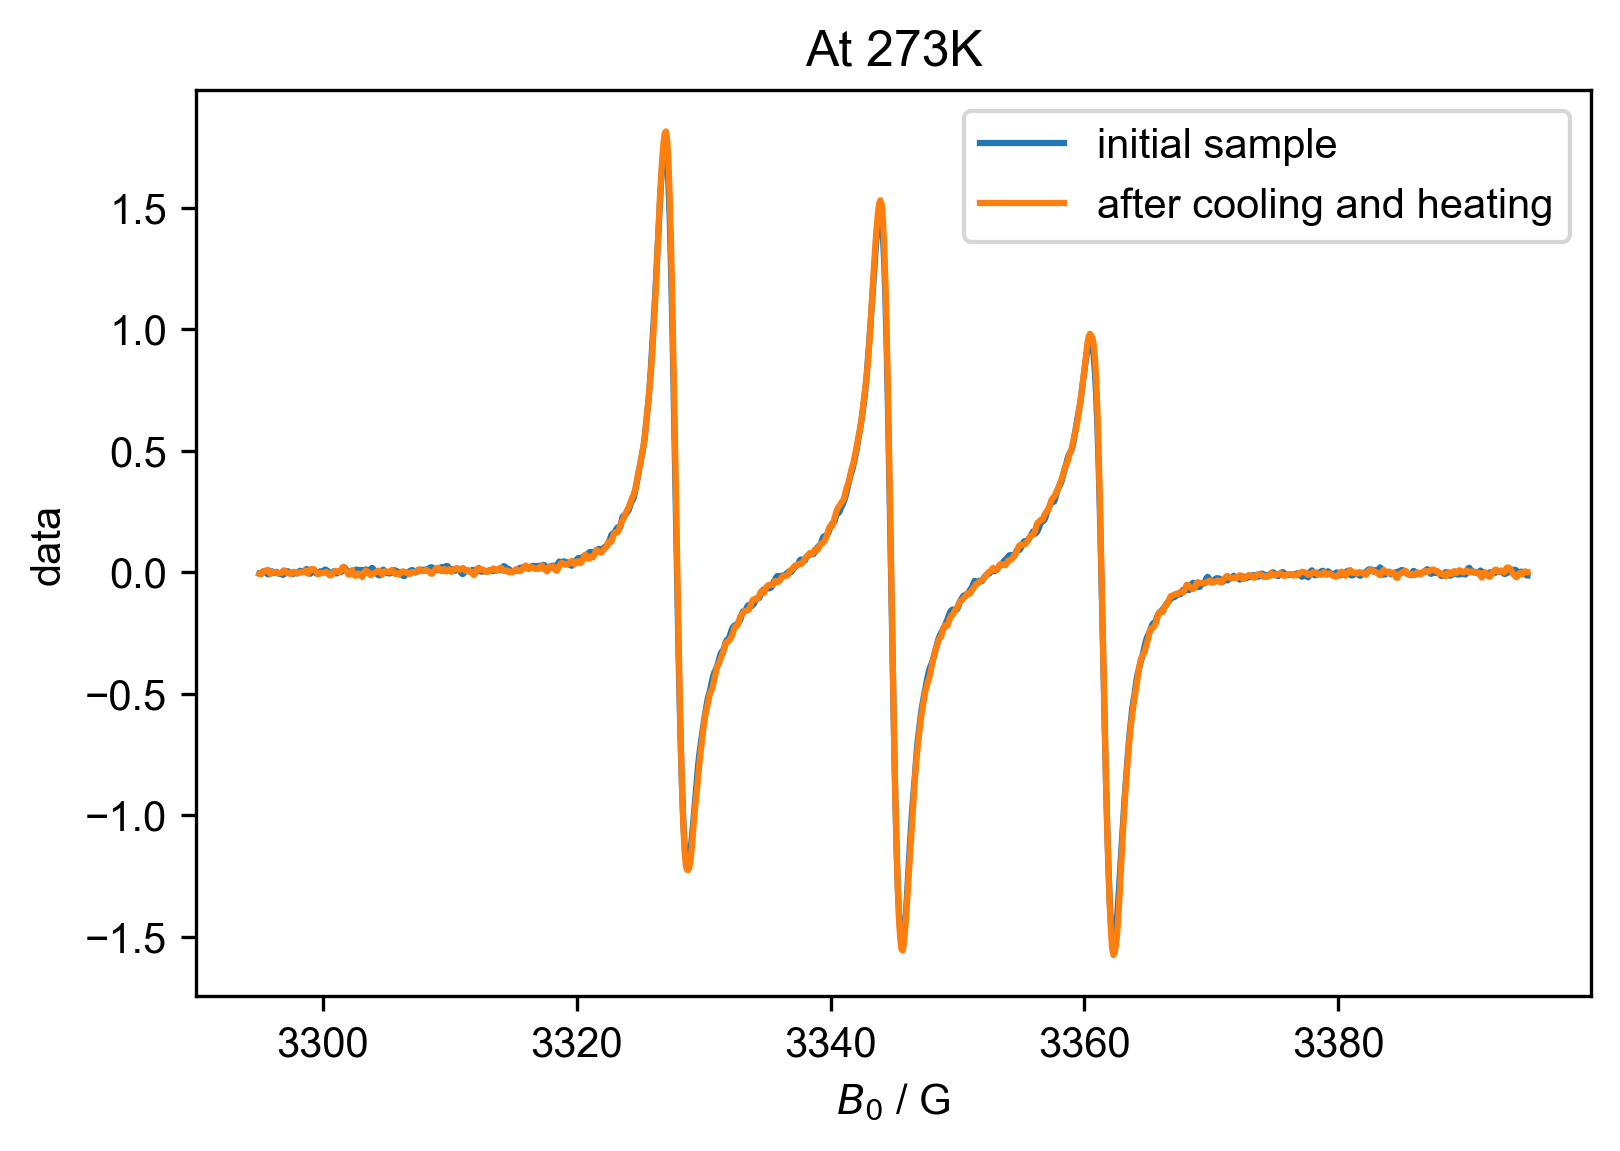

In [13]:
#near room temperature
print(d1.getaxis("Temperature"))
print(d2.getaxis("Temperature"))
figure(dpi=300, figsize=(6,4))
plot(d1["Temperature":273], label="initial sample")
plot(d2["Temperature":273], label="after cooling and heating")
title("At 273K")
legend()

[253.314 253.552 255.388 255.48  257.482 257.666 258.532 260.159 260.498
 261.453 263.293 263.592 264.557 265.711 266.568 267.641 268.699 269.832
 270.628 272.393 272.636 273.651 274.757 276.42  276.788 278.363 279.404
 279.558 280.548 282.705 282.984]
[252.931 253.817 254.821 255.823 256.679 257.705 258.86  259.883 260.694
 262.354 263.462 264.347 264.633 266.295 267.343 267.835 269.382 270.307
 270.461 272.457 273.435 273.612 275.239 275.582 277.411 277.5   279.163
 279.608 281.131 281.917 282.31 ]


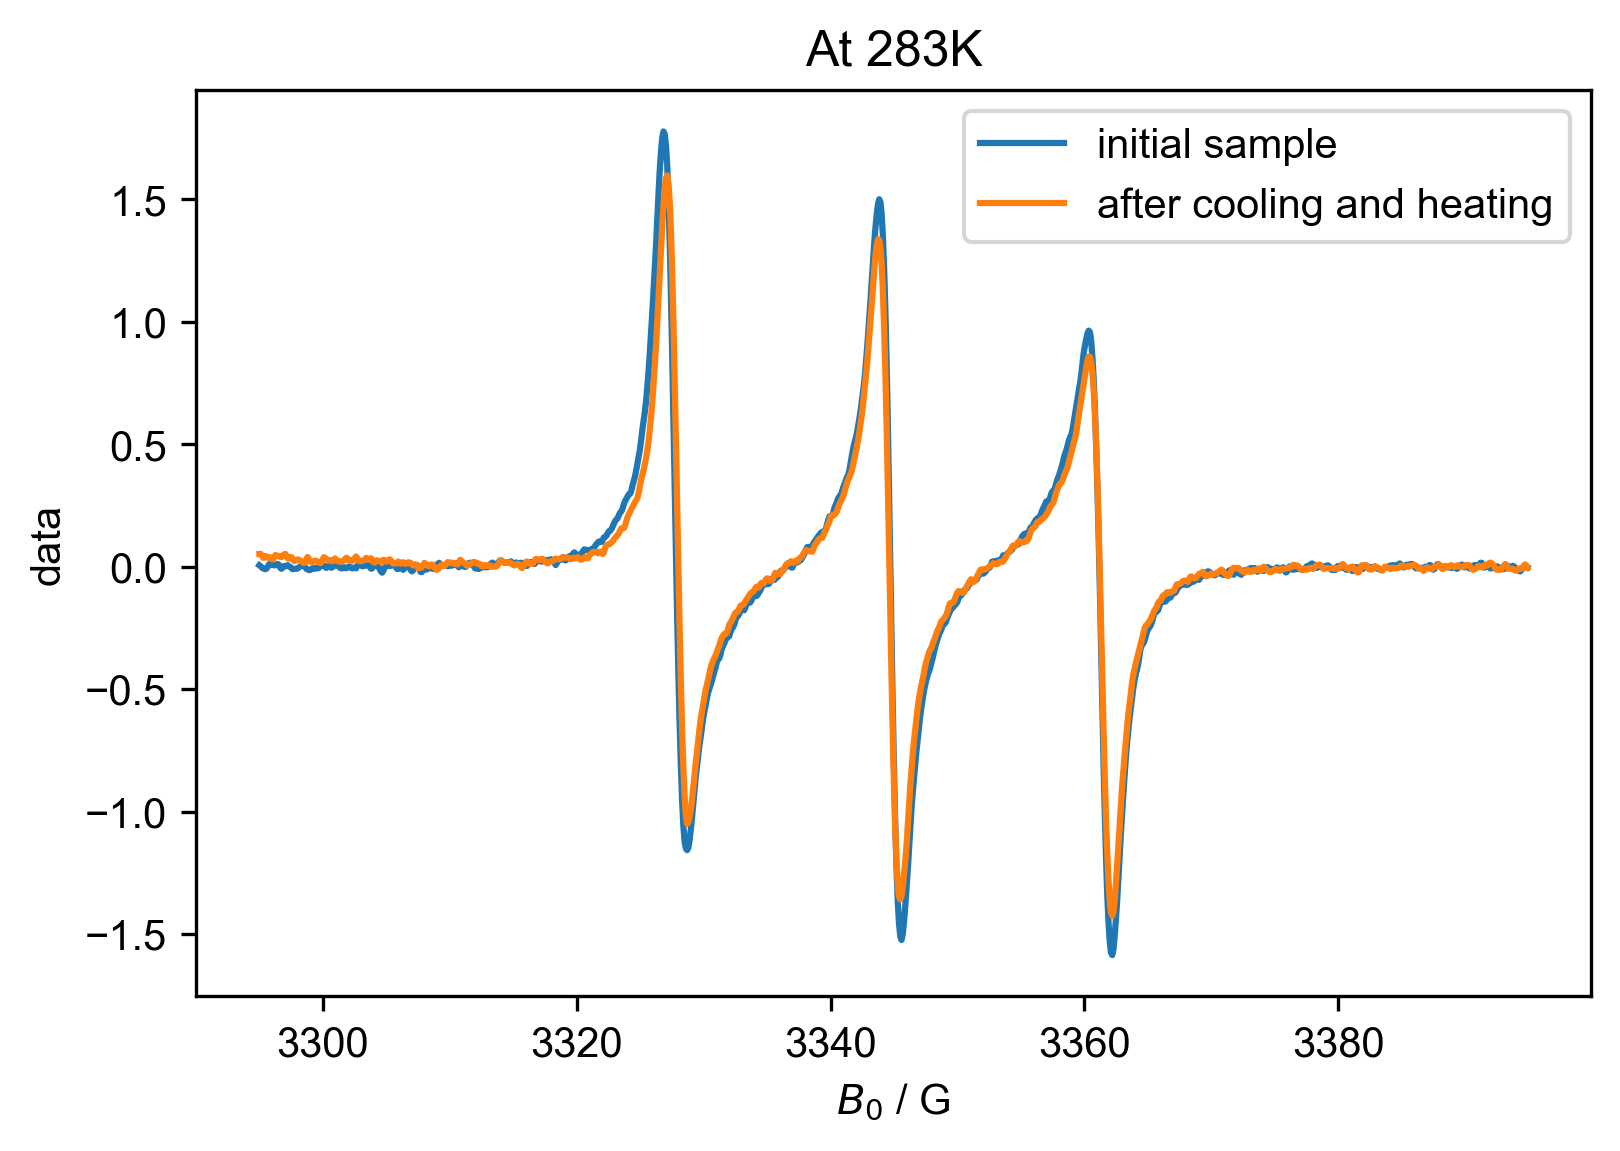

In [14]:
#near room temperature
print(d1.getaxis("Temperature"))
print(d2.getaxis("Temperature"))
figure(dpi=300, figsize=(6,4))
plot(d1["Temperature":283], label="initial sample")
plot(d2["Temperature":283], label="after cooling and heating")
title("At 283K")
legend()

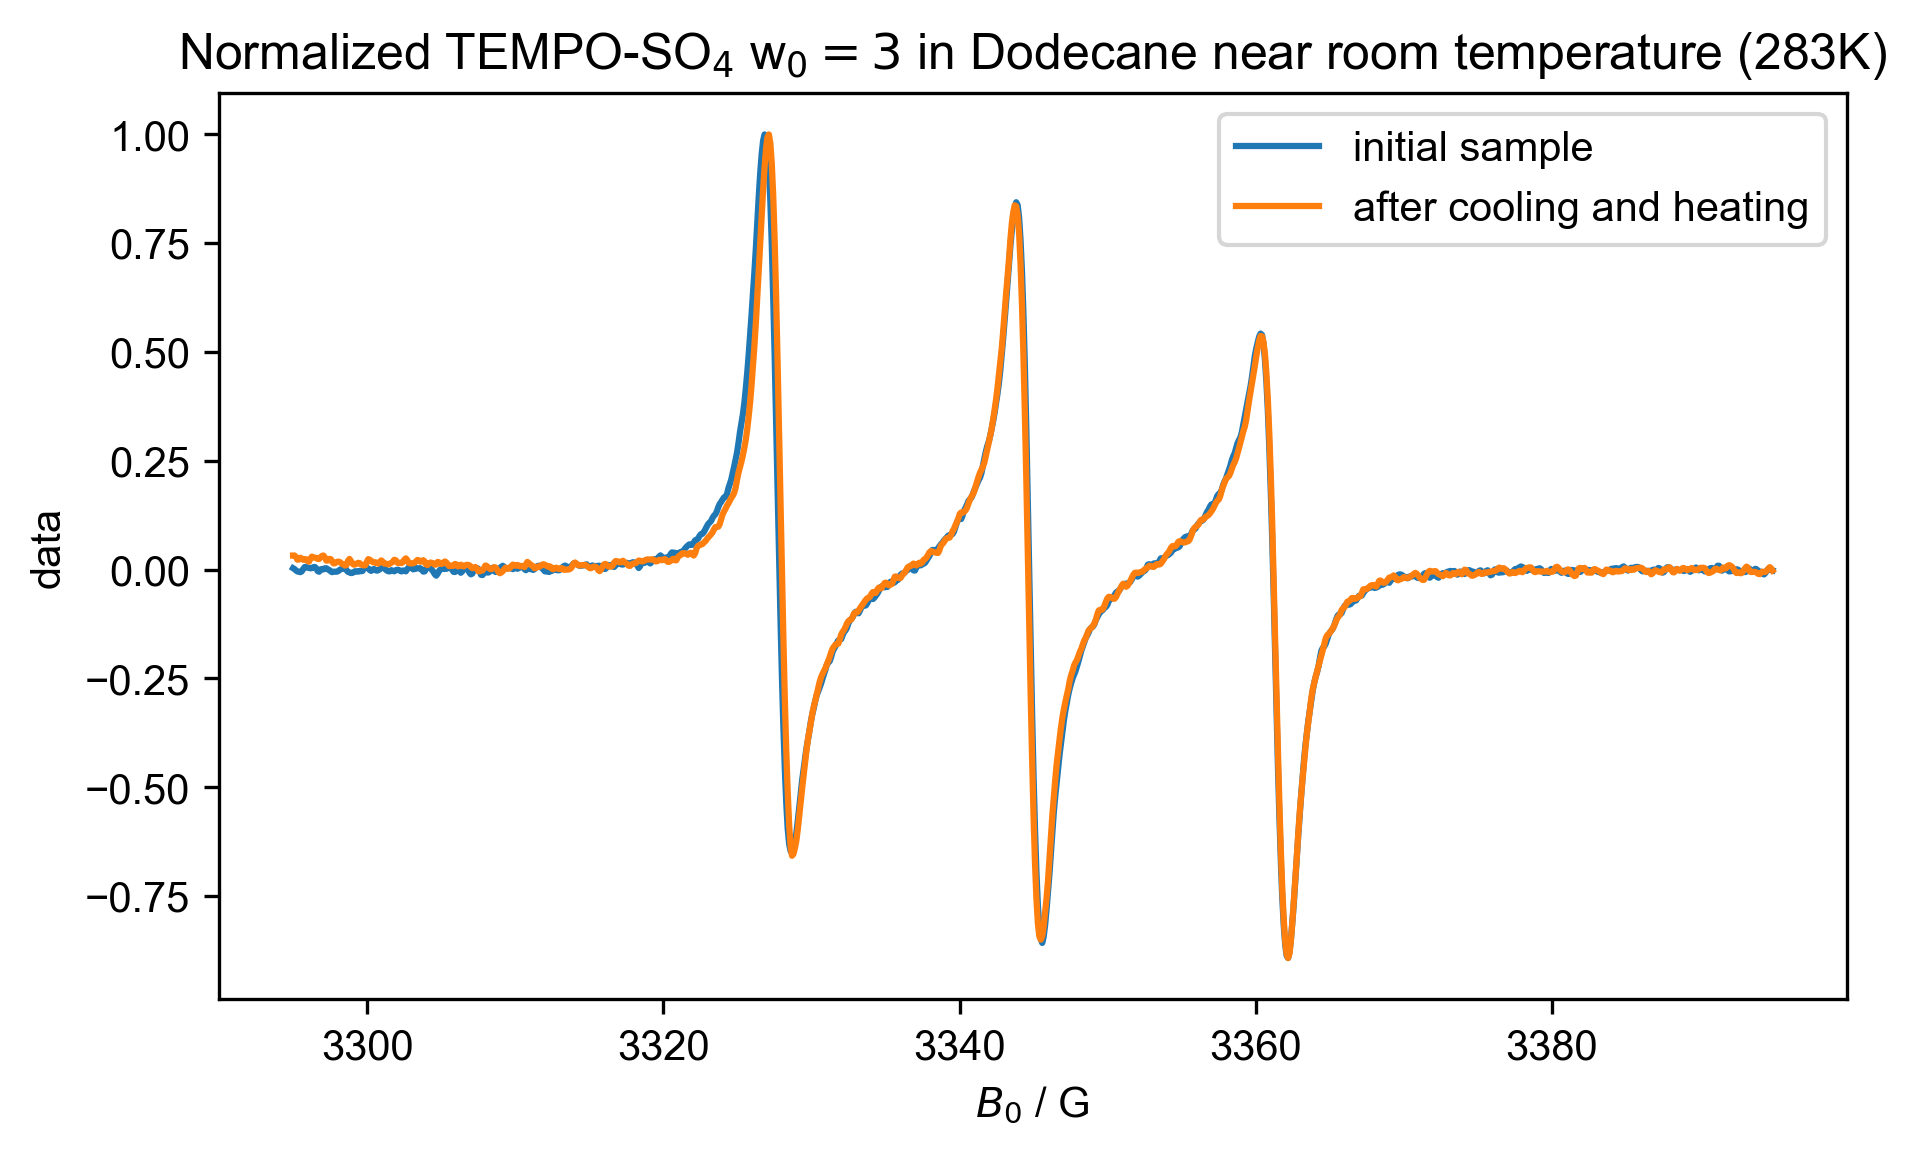

In [15]:
#Normalized
figure(dpi=300, figsize=(7,4))
plot(d1["Temperature": 283] / d1["Temperature": 283].max(), label= "initial sample")
plot(d2["Temperature": 283] / d2["Temperature": 283].max(), label= "after cooling and heating")
title("Normalized TEMPO-SO$_4$ w$_0= 3$ in Dodecane near room temperature (283K)")
legend()